# Adversarial CV Speed Limit Sign — Results Analysis

Load and parse all 21 result tables from `src/modelling/final_final_results_i_promise/` into a unified DataFrame following the schema:
`preprocessing, model, postprocessing, dataset, metric1, metric2, ..., time metrics, ...`

In [17]:
import glob
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

RESULTS_DIR = "../modelling/final_final_results_i_promise"

def parse_table(filepath: str):
    """Parse a fixed-width result table .txt file into (metric_name, DataFrame)."""
    with open(filepath, "r", encoding="utf-8") as f:
        lines = [line.rstrip("\r\n") for line in f if line.strip()]
    metric_name = lines[0].split("Metric:")[1].strip()
    header_line = lines[1]
    dash_line = lines[2]
    colspecs = [(m.start(), m.end()) for m in re.finditer(r"-+", dash_line)]
    headers = [header_line[s:e].strip() for s, e in colspecs]
    rows = [[line[s:e].strip() for s, e in colspecs] for line in lines[3:]]
    df = pd.DataFrame(rows, columns=headers)
    for col in headers[3:]:
        df[col] = pd.to_numeric(df[col])
    df = df.rename(columns={
        "Preprocessing": "preprocessing",
        "Model": "model",
        "Postprocessing": "postprocessing",
    })
    return metric_name, df

## Join All Metric & Runtime Tables into One Big Table

In [18]:
key_cols = ["preprocessing", "model", "postprocessing"]
metric_dfs = []
runtime_df = None

for filepath in sorted(glob.glob(os.path.join(RESULTS_DIR, "*.txt"))):
    metric_name, df = parse_table(filepath)
    if metric_name == "runtime":
        runtime_df = df
    else:
        melted = df.melt(
            id_vars=key_cols,
            var_name="dataset",
            value_name=metric_name,
        )
        metric_dfs.append(melted.set_index(key_cols + ["dataset"]))

big_df = pd.concat(metric_dfs, axis=1).reset_index()
big_df = big_df.merge(runtime_df, on=key_cols, how="left")

print(f"Combined table shape: {big_df.shape}")
print(f"Columns ({len(big_df.columns)}): {list(big_df.columns)}")
big_df.head(10)

Combined table shape: (1152, 30)
Columns (30): ['preprocessing', 'model', 'postprocessing', 'dataset', 'accuracy', 'average_precision_macro', 'average_precision_weighted', 'balanced_accuracy', 'cohen_kappa', 'cross_entropy_loss', 'f1_macro', 'f1_micro', 'f1_weighted', 'matthews_correlation_coefficient', 'precision_macro', 'precision_micro', 'precision_weighted', 'recall_macro', 'recall_micro', 'recall_weighted', 'roc_auc_macro_ovr', 'roc_auc_weighted_ovr', 'top_3_accuracy', 'top_5_accuracy', 'Total Runtime (s)', 'Avg Runtime (s)', 'Total Runs', 'Inferences per Run', 'Avg Time per Inference (s)', 'Avg Time per Inference (ms)']


,preprocessing,model,postprocessing,dataset,accuracy,average_precision_macro,average_precision_weighted,balanced_accuracy,cohen_kappa,cross_entropy_loss,f1_macro,f1_micro,f1_weighted,matthews_correlation_coefficient,precision_macro,precision_micro,precision_weighted,recall_macro,recall_micro,recall_weighted,roc_auc_macro_ovr,roc_auc_weighted_ovr,top_3_accuracy,top_5_accuracy,Total Runtime (s),Avg Runtime (s),Total Runs,Inferences per Run,Avg Time per Inference (s),Avg Time per Inference (ms)
0,none,baseline,none,clean_test,1.000000,1.000000,1.000000,1.000000,1.000000,0.028246,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,11.451279,3.817093,3,460,0.008298,8.2980
1,none,baseline,revsig,clean_test,1.000000,0.686113,0.810590,1.000000,1.000000,1.905913,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.935127,0.965887,1.000000,1.000000,8.099982,2.699994,3,460,0.005870,5.8696
2,none,baseline,noise,clean_test,1.000000,1.000000,1.000000,1.000000,1.000000,0.418310,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.970618,2.656873,3,460,0.005776,5.7758
3,none,baseline,highconf,clean_test,1.000000,1.000000,1.000000,1.000000,1.000000,0.019004,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.147854,2.715951,3,460,0.005904,5.9042
4,none,baseline,revsig -> noise,clean_test,0.130435,0.194082,0.242667,0.114495,-0.014467,8.658283,0.114740,0.130435,0.137748,-0.014966,0.122913,0.130435,0.161124,0.114495,0.130435,0.130435,0.514055,0.528136,0.469565,0.686957,8.087452,2.695817,3,460,0.005860,5.8605
5,none,baseline,revsig -> highconf,clean_test,1.000000,0.686113,0.810590,1.000000,1.000000,1.905913,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.935127,0.965887,1.000000,1.000000,8.098875,2.699625,3,460,0.005869,5.8687
6,none,baseline,noise -> revsig,clean_test,0.878261,0.911083,0.911844,0.893660,0.852104,1.721913,0.886762,0.878261,0.891519,0.858262,0.906073,0.878261,0.926632,0.893660,0.878261,0.878261,0.965557,0.963442,0.982609,1.000000,8.109991,2.703330,3,460,0.005877,5.8768
7,none,baseline,noise -> highconf,clean_test,1.000000,1.000000,1.000000,1.000000,1.000000,0.352921,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.104834,2.701611,3,460,0.005873,5.8731
8,none,baseline,highconf -> revsig,clean_test,1.000000,0.753046,0.850500,1.000000,1.000000,1.920782,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.975557,0.980318,1.000000,1.000000,8.059253,2.686418,3,460,0.005840,5.8400
9,none,baseline,highconf -> noise,clean_test,1.000000,1.000000,1.000000,1.000000,1.000000,0.413646,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.987652,2.662551,3,460,0.005788,5.7882


## 1. Sort by Fastest Method
Sorted by `Avg Time per Inference (ms)` ascending across all `(preprocessing, model, postprocessing, dataset)` rows.

In [19]:
summary_cols = [
    "preprocessing", "model", "postprocessing", "dataset",
    "accuracy", "f1_macro", "f1_weighted", "f1_micro",
    "Avg Time per Inference (ms)", "Avg Runtime (s)", "Total Runtime (s)"
]

fastest_df = big_df.sort_values("Avg Time per Inference (ms)", ascending=True)
fastest_df[summary_cols].head(20)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
79,none,adversarial_retrained,highconf -> noise -> revsig,clean_test,0.947826,0.948198,0.950450,0.947826,5.3769,2.473363,7.420090
655,none,adversarial_retrained,highconf -> noise -> revsig,pixle_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
367,none,adversarial_retrained,highconf -> noise -> revsig,pgd_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
943,none,adversarial_retrained,highconf -> noise -> revsig,pgdpixle_test,0.947826,0.945797,0.949239,0.947826,5.3769,2.473363,7.420090
647,none,adversarial_retrained,noise -> highconf,pixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
71,none,adversarial_retrained,noise -> highconf,clean_test,1.000000,1.000000,1.000000,1.000000,5.3960,2.482145,7.446436
935,none,adversarial_retrained,noise -> highconf,pgdpixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
359,none,adversarial_retrained,noise -> highconf,pgd_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
938,none,adversarial_retrained,revsig -> noise -> highconf,pgdpixle_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
74,none,adversarial_retrained,revsig -> noise -> highconf,clean_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564


## 2. Sort by Fastest Method, Then Sort by Best F1
### 2a. Exact Multi-Column Sort (`Avg Time per Inference (ms)` ASC, `f1_macro` DESC)
Because each `(preprocessing, model, postprocessing)` pipeline is evaluated on 4 datasets (`clean_test`, `pgd_test`, `pixle_test`, `pgdpixle_test`) with the same pipeline runtime, sorting by exact runtime first and `f1_macro` second orders datasets from highest F1 to lowest F1 within each fastest pipeline.

In [20]:
fastest_then_f1_exact = big_df.sort_values(
    by=["Avg Time per Inference (ms)", "f1_macro"],
    ascending=[True, False]
)
fastest_then_f1_exact[summary_cols].head(20)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
79,none,adversarial_retrained,highconf -> noise -> revsig,clean_test,0.947826,0.948198,0.950450,0.947826,5.3769,2.473363,7.420090
943,none,adversarial_retrained,highconf -> noise -> revsig,pgdpixle_test,0.947826,0.945797,0.949239,0.947826,5.3769,2.473363,7.420090
367,none,adversarial_retrained,highconf -> noise -> revsig,pgd_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
655,none,adversarial_retrained,highconf -> noise -> revsig,pixle_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
71,none,adversarial_retrained,noise -> highconf,clean_test,1.000000,1.000000,1.000000,1.000000,5.3960,2.482145,7.446436
359,none,adversarial_retrained,noise -> highconf,pgd_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
647,none,adversarial_retrained,noise -> highconf,pixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
935,none,adversarial_retrained,noise -> highconf,pgdpixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
74,none,adversarial_retrained,revsig -> noise -> highconf,clean_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
362,none,adversarial_retrained,revsig -> noise -> highconf,pgd_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564


### 2b. Rounded Time-Tier Sort (`time_tier_ms` ASC, `f1_macro` DESC)
Rounding inference time to the nearest millisecond (`time_tier_ms = 5 ms`) groups methods in the same speed tier so small timing jitter (~0.02 ms) does not rank a low-F1 method above a 1.000 F1 method.

In [21]:
big_df["time_tier_ms"] = big_df["Avg Time per Inference (ms)"].round(0)
fastest_tier_then_f1 = big_df.sort_values(
    by=["time_tier_ms", "f1_macro", "Avg Time per Inference (ms)"],
    ascending=[True, False, True]
)
fastest_tier_then_f1[summary_cols + ["time_tier_ms"]].head(20)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s),time_tier_ms
71,none,adversarial_retrained,noise -> highconf,clean_test,1.000000,1.00000,1.00000,1.000000,5.3960,2.482145,7.446436,5.0
67,none,adversarial_retrained,highconf,clean_test,1.000000,1.00000,1.00000,1.000000,5.4175,2.492071,7.476214,5.0
73,none,adversarial_retrained,highconf -> noise,clean_test,1.000000,1.00000,1.00000,1.000000,5.4481,2.506142,7.518425,5.0
66,none,adversarial_retrained,noise,clean_test,1.000000,1.00000,1.00000,1.000000,5.4499,2.506971,7.520914,5.0
72,none,adversarial_retrained,highconf -> revsig,clean_test,1.000000,1.00000,1.00000,1.000000,5.4622,2.512597,7.537790,5.0
69,none,adversarial_retrained,revsig -> highconf,clean_test,1.000000,1.00000,1.00000,1.000000,5.4662,2.514437,7.543311,5.0
65,none,adversarial_retrained,revsig,clean_test,1.000000,1.00000,1.00000,1.000000,5.4696,2.515998,7.547993,5.0
359,none,adversarial_retrained,noise -> highconf,pgd_test,0.991304,0.98936,0.99128,0.991304,5.3960,2.482145,7.446436,5.0
647,none,adversarial_retrained,noise -> highconf,pixle_test,0.991304,0.98936,0.99128,0.991304,5.3960,2.482145,7.446436,5.0
935,none,adversarial_retrained,noise -> highconf,pgdpixle_test,0.991304,0.98936,0.99128,0.991304,5.3960,2.482145,7.446436,5.0


### 2c. Pipeline-Level Summary (Mean Across All 4 Datasets): Fastest Tier + Best Mean F1

In [22]:
agg_pipeline_df = (
    big_df.groupby(key_cols, as_index=False)[
        ["accuracy", "f1_macro", "f1_weighted", "Avg Time per Inference (ms)", "Avg Runtime (s)", "Total Runtime (s)"]
    ]
    .mean()
)
agg_pipeline_df["time_tier_ms"] = agg_pipeline_df["Avg Time per Inference (ms)"].round(0)
agg_pipeline_df.sort_values(
    by=["time_tier_ms", "f1_macro", "Avg Time per Inference (ms)"],
    ascending=[True, False, True]
).head(15)

,preprocessing,model,postprocessing,accuracy,f1_macro,f1_weighted,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s),time_tier_ms
214,none,adversarial_retrained,noise -> highconf,0.993478,0.992020,0.993460,5.3960,2.482145,7.446436,5.0
208,none,adversarial_retrained,highconf,0.993478,0.992020,0.993460,5.4175,2.492071,7.476214,5.0
209,none,adversarial_retrained,highconf -> noise,0.993478,0.992020,0.993460,5.4481,2.506142,7.518425,5.0
213,none,adversarial_retrained,noise,0.993478,0.992020,0.993460,5.4499,2.506971,7.520914,5.0
211,none,adversarial_retrained,highconf -> revsig,0.993478,0.992020,0.993460,5.4622,2.512597,7.537790,5.0
220,none,adversarial_retrained,revsig -> highconf,0.993478,0.992020,0.993460,5.4662,2.514437,7.543311,5.0
219,none,adversarial_retrained,revsig,0.993478,0.992020,0.993460,5.4696,2.515998,7.547993,5.0
275,none,robust,highconf -> revsig,0.973913,0.982614,0.974332,5.4841,2.522680,7.568039,5.0
273,none,robust,highconf -> noise,0.971739,0.981224,0.972225,5.4755,2.518737,7.556212,5.0
277,none,robust,noise,0.971739,0.981224,0.972225,5.4936,2.527073,7.581219,5.0


## 3. Scatterplot: Inference Time vs. F1 Macro Score

---
# Per-Dataset Analysis (`clean_test`, `pgd_test`, `pixle_test`, `pgdpixle_test`)

Below we run the same analysis separately for each of the 4 evaluation datasets:
1. **Sort by fastest method** (`Avg Time per Inference (ms)` ascending)
2. **Sort by fastest then sort by best F1** (shown both as `["Avg Time per Inference (ms)", "f1_macro"]` and sequential sort `sort_values("Avg Time per Inference (ms)").sort_values("f1_macro", ascending=False, kind="stable")` where ties in F1 are ordered by fastest runtime)

## Dataset: `clean_test`
### 1. `clean_test` — Sort by Fastest Method

In [23]:
clean_test_df = big_df[big_df["dataset"] == "clean_test"].copy()
clean_test_fastest = clean_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
clean_test_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
79,none,adversarial_retrained,highconf -> noise -> revsig,clean_test,0.947826,0.948198,0.950450,0.947826,5.3769,2.473363,7.420090
71,none,adversarial_retrained,noise -> highconf,clean_test,1.000000,1.000000,1.000000,1.000000,5.3960,2.482145,7.446436
74,none,adversarial_retrained,revsig -> noise -> highconf,clean_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
67,none,adversarial_retrained,highconf,clean_test,1.000000,1.000000,1.000000,1.000000,5.4175,2.492071,7.476214
206,none,grl,highconf -> revsig -> noise,clean_test,0.130435,0.114740,0.137748,0.130435,5.4284,2.497085,7.491256
76,none,adversarial_retrained,noise -> revsig -> highconf,clean_test,0.913043,0.914893,0.921053,0.913043,5.4312,2.498368,7.495103
75,none,adversarial_retrained,revsig -> highconf -> noise,clean_test,0.130435,0.114740,0.137748,0.130435,5.4319,2.498684,7.496053
140,none,robust,noise -> revsig -> highconf,clean_test,0.878261,0.889934,0.886892,0.878261,5.4326,2.499016,7.497047
68,none,adversarial_retrained,revsig -> noise,clean_test,0.130435,0.114740,0.137748,0.130435,5.4335,2.499414,7.498243
205,none,grl,noise -> highconf -> revsig,clean_test,0.895652,0.851171,0.904498,0.895652,5.4349,2.500058,7.500174


### 2a. `clean_test` — Sort by Fastest, Then Best F1 (`["Avg Time per Inference (ms)", "f1_macro"]`)

In [39]:
clean_test_fastest_then_f1 = clean_test_df.sort_values(
    by=["f1_macro", "Avg Time per Inference (ms)"],
    ascending=[False, True]
)
clean_test_fastest_then_f1[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
71,none,adversarial_retrained,noise -> highconf,clean_test,1.0,1.0,1.0,1.0,5.3960,2.482145,7.446436
67,none,adversarial_retrained,highconf,clean_test,1.0,1.0,1.0,1.0,5.4175,2.492071,7.476214
73,none,adversarial_retrained,highconf -> noise,clean_test,1.0,1.0,1.0,1.0,5.4481,2.506142,7.518425
66,none,adversarial_retrained,noise,clean_test,1.0,1.0,1.0,1.0,5.4499,2.506971,7.520914
72,none,adversarial_retrained,highconf -> revsig,clean_test,1.0,1.0,1.0,1.0,5.4622,2.512597,7.537790
69,none,adversarial_retrained,revsig -> highconf,clean_test,1.0,1.0,1.0,1.0,5.4662,2.514437,7.543311
65,none,adversarial_retrained,revsig,clean_test,1.0,1.0,1.0,1.0,5.4696,2.515998,7.547993
2,none,baseline,noise,clean_test,1.0,1.0,1.0,1.0,5.7758,2.656873,7.970618
9,none,baseline,highconf -> noise,clean_test,1.0,1.0,1.0,1.0,5.7882,2.662551,7.987652
8,none,baseline,highconf -> revsig,clean_test,1.0,1.0,1.0,1.0,5.8400,2.686418,8.059253


### 2b. `clean_test` — Sort by Fastest, Then Sort by Best F1 (`f1_macro` DESC, Fastest Tie-Breaker)

In [25]:
clean_test_best_f1_fastest = (
    clean_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
    .sort_values("f1_macro", ascending=False, kind="mergesort")
)
clean_test_best_f1_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
71,none,adversarial_retrained,noise -> highconf,clean_test,1.0,1.0,1.0,1.0,5.3960,2.482145,7.446436
67,none,adversarial_retrained,highconf,clean_test,1.0,1.0,1.0,1.0,5.4175,2.492071,7.476214
73,none,adversarial_retrained,highconf -> noise,clean_test,1.0,1.0,1.0,1.0,5.4481,2.506142,7.518425
66,none,adversarial_retrained,noise,clean_test,1.0,1.0,1.0,1.0,5.4499,2.506971,7.520914
72,none,adversarial_retrained,highconf -> revsig,clean_test,1.0,1.0,1.0,1.0,5.4622,2.512597,7.537790
69,none,adversarial_retrained,revsig -> highconf,clean_test,1.0,1.0,1.0,1.0,5.4662,2.514437,7.543311
65,none,adversarial_retrained,revsig,clean_test,1.0,1.0,1.0,1.0,5.4696,2.515998,7.547993
2,none,baseline,noise,clean_test,1.0,1.0,1.0,1.0,5.7758,2.656873,7.970618
9,none,baseline,highconf -> noise,clean_test,1.0,1.0,1.0,1.0,5.7882,2.662551,7.987652
8,none,baseline,highconf -> revsig,clean_test,1.0,1.0,1.0,1.0,5.8400,2.686418,8.059253


## Dataset: `pgd_test`
### 1. `pgd_test` — Sort by Fastest Method

In [26]:
pgd_test_df = big_df[big_df["dataset"] == "pgd_test"].copy()
pgd_test_fastest = pgd_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
pgd_test_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
367,none,adversarial_retrained,highconf -> noise -> revsig,pgd_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
359,none,adversarial_retrained,noise -> highconf,pgd_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
362,none,adversarial_retrained,revsig -> noise -> highconf,pgd_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
355,none,adversarial_retrained,highconf,pgd_test,0.991304,0.989360,0.991280,0.991304,5.4175,2.492071,7.476214
494,none,grl,highconf -> revsig -> noise,pgd_test,0.130435,0.114190,0.137146,0.130435,5.4284,2.497085,7.491256
364,none,adversarial_retrained,noise -> revsig -> highconf,pgd_test,0.904348,0.904344,0.912410,0.904348,5.4312,2.498368,7.495103
363,none,adversarial_retrained,revsig -> highconf -> noise,pgd_test,0.130435,0.114740,0.137748,0.130435,5.4319,2.498684,7.496053
428,none,robust,noise -> revsig -> highconf,pgd_test,0.869565,0.884652,0.879562,0.869565,5.4326,2.499016,7.497047
356,none,adversarial_retrained,revsig -> noise,pgd_test,0.130435,0.114740,0.137748,0.130435,5.4335,2.499414,7.498243
493,none,grl,noise -> highconf -> revsig,pgd_test,0.878261,0.832028,0.892378,0.878261,5.4349,2.500058,7.500174


### 2a. `pgd_test` — Sort by Fastest, Then Best F1 (`["Avg Time per Inference (ms)", "f1_macro"]`)

In [38]:
pgd_test_fastest_then_f1 = pgd_test_df.sort_values(
    by=["f1_macro", "Avg Time per Inference (ms)"],
    ascending=[False, True]
)
pgd_test_fastest_then_f1[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
552,none,convae_rn50,highconf -> revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4574,2.970422,8.911265
545,none,convae_rn50,revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4648,2.973827,8.921480
547,none,convae_rn50,highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4800,2.980785,8.942354
551,none,convae_rn50,noise -> highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5005,2.990225,8.970676
553,none,convae_rn50,highconf -> noise,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5160,2.997360,8.992079
549,none,convae_rn50,revsig -> highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5345,3.005892,9.017675
546,none,convae_rn50,noise,pgd_test,0.991304,0.994069,0.991359,0.991304,6.6539,3.060811,9.182432
544,none,convae_rn50,none,pgd_test,0.991304,0.994069,0.991359,0.991304,9.0571,4.166281,12.498843
563,jpeg -> median -> gaussian,convae_rn50,highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,182.9872,84.174103,252.522309
568,jpeg -> median -> gaussian,convae_rn50,highconf -> revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,183.2340,84.287621,252.862864


### 2b. `pgd_test` — Sort by Fastest, Then Sort by Best F1 (`f1_macro` DESC, Fastest Tie-Breaker)

In [28]:
pgd_test_best_f1_fastest = (
    pgd_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
    .sort_values("f1_macro", ascending=False, kind="mergesort")
)
pgd_test_best_f1_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
552,none,convae_rn50,highconf -> revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4574,2.970422,8.911265
545,none,convae_rn50,revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4648,2.973827,8.921480
547,none,convae_rn50,highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.4800,2.980785,8.942354
551,none,convae_rn50,noise -> highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5005,2.990225,8.970676
553,none,convae_rn50,highconf -> noise,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5160,2.997360,8.992079
549,none,convae_rn50,revsig -> highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,6.5345,3.005892,9.017675
546,none,convae_rn50,noise,pgd_test,0.991304,0.994069,0.991359,0.991304,6.6539,3.060811,9.182432
544,none,convae_rn50,none,pgd_test,0.991304,0.994069,0.991359,0.991304,9.0571,4.166281,12.498843
563,jpeg -> median -> gaussian,convae_rn50,highconf,pgd_test,0.991304,0.994069,0.991359,0.991304,182.9872,84.174103,252.522309
568,jpeg -> median -> gaussian,convae_rn50,highconf -> revsig,pgd_test,0.991304,0.994069,0.991359,0.991304,183.2340,84.287621,252.862864


## Dataset: `pixle_test`
### 1. `pixle_test` — Sort by Fastest Method

In [29]:
pixle_test_df = big_df[big_df["dataset"] == "pixle_test"].copy()
pixle_test_fastest = pixle_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
pixle_test_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
655,none,adversarial_retrained,highconf -> noise -> revsig,pixle_test,0.939130,0.937558,0.941731,0.939130,5.3769,2.473363,7.420090
647,none,adversarial_retrained,noise -> highconf,pixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
650,none,adversarial_retrained,revsig -> noise -> highconf,pixle_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
643,none,adversarial_retrained,highconf,pixle_test,0.991304,0.989360,0.991280,0.991304,5.4175,2.492071,7.476214
782,none,grl,highconf -> revsig -> noise,pixle_test,0.130435,0.114740,0.137748,0.130435,5.4284,2.497085,7.491256
652,none,adversarial_retrained,noise -> revsig -> highconf,pixle_test,0.904348,0.904344,0.912410,0.904348,5.4312,2.498368,7.495103
651,none,adversarial_retrained,revsig -> highconf -> noise,pixle_test,0.130435,0.114740,0.137748,0.130435,5.4319,2.498684,7.496053
716,none,robust,noise -> revsig -> highconf,pixle_test,0.869565,0.884652,0.879562,0.869565,5.4326,2.499016,7.497047
644,none,adversarial_retrained,revsig -> noise,pixle_test,0.130435,0.114740,0.137748,0.130435,5.4335,2.499414,7.498243
781,none,grl,noise -> highconf -> revsig,pixle_test,0.895652,0.851171,0.904498,0.895652,5.4349,2.500058,7.500174


### 2a. `pixle_test` — Sort by Fastest, Then Best F1 (`["Avg Time per Inference (ms)", "f1_macro"]`)

In [37]:
pixle_test_fastest_then_f1 = pixle_test_df.sort_values(
    by=["f1_macro", "Avg Time per Inference (ms)"],
    ascending=[False, True]
)
pixle_test_fastest_then_f1[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
840,none,convae_rn50,highconf -> revsig,pixle_test,1.0,1.0,1.0,1.0,6.4574,2.970422,8.911265
833,none,convae_rn50,revsig,pixle_test,1.0,1.0,1.0,1.0,6.4648,2.973827,8.921480
835,none,convae_rn50,highconf,pixle_test,1.0,1.0,1.0,1.0,6.4800,2.980785,8.942354
839,none,convae_rn50,noise -> highconf,pixle_test,1.0,1.0,1.0,1.0,6.5005,2.990225,8.970676
841,none,convae_rn50,highconf -> noise,pixle_test,1.0,1.0,1.0,1.0,6.5160,2.997360,8.992079
837,none,convae_rn50,revsig -> highconf,pixle_test,1.0,1.0,1.0,1.0,6.5345,3.005892,9.017675
834,none,convae_rn50,noise,pixle_test,1.0,1.0,1.0,1.0,6.6539,3.060811,9.182432
832,none,convae_rn50,none,pixle_test,1.0,1.0,1.0,1.0,9.0571,4.166281,12.498843
677,jpeg -> median -> gaussian,adversarial_retrained,revsig -> highconf,pixle_test,1.0,1.0,1.0,1.0,163.5831,75.248225,225.744676
609,jpeg -> median -> gaussian,baseline,revsig,pixle_test,1.0,1.0,1.0,1.0,164.0741,75.474075,226.422225


### 2b. `pixle_test` — Sort by Fastest, Then Sort by Best F1 (`f1_macro` DESC, Fastest Tie-Breaker)

In [31]:
pixle_test_best_f1_fastest = (
    pixle_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
    .sort_values("f1_macro", ascending=False, kind="mergesort")
)
pixle_test_best_f1_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
840,none,convae_rn50,highconf -> revsig,pixle_test,1.0,1.0,1.0,1.0,6.4574,2.970422,8.911265
833,none,convae_rn50,revsig,pixle_test,1.0,1.0,1.0,1.0,6.4648,2.973827,8.921480
835,none,convae_rn50,highconf,pixle_test,1.0,1.0,1.0,1.0,6.4800,2.980785,8.942354
839,none,convae_rn50,noise -> highconf,pixle_test,1.0,1.0,1.0,1.0,6.5005,2.990225,8.970676
841,none,convae_rn50,highconf -> noise,pixle_test,1.0,1.0,1.0,1.0,6.5160,2.997360,8.992079
837,none,convae_rn50,revsig -> highconf,pixle_test,1.0,1.0,1.0,1.0,6.5345,3.005892,9.017675
834,none,convae_rn50,noise,pixle_test,1.0,1.0,1.0,1.0,6.6539,3.060811,9.182432
832,none,convae_rn50,none,pixle_test,1.0,1.0,1.0,1.0,9.0571,4.166281,12.498843
677,jpeg -> median -> gaussian,adversarial_retrained,revsig -> highconf,pixle_test,1.0,1.0,1.0,1.0,163.5831,75.248225,225.744676
609,jpeg -> median -> gaussian,baseline,revsig,pixle_test,1.0,1.0,1.0,1.0,164.0741,75.474075,226.422225


## Dataset: `pgdpixle_test`
### 1. `pgdpixle_test` — Sort by Fastest Method

In [32]:
pgdpixle_test_df = big_df[big_df["dataset"] == "pgdpixle_test"].copy()
pgdpixle_test_fastest = pgdpixle_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
pgdpixle_test_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
943,none,adversarial_retrained,highconf -> noise -> revsig,pgdpixle_test,0.947826,0.945797,0.949239,0.947826,5.3769,2.473363,7.420090
935,none,adversarial_retrained,noise -> highconf,pgdpixle_test,0.991304,0.989360,0.991280,0.991304,5.3960,2.482145,7.446436
938,none,adversarial_retrained,revsig -> noise -> highconf,pgdpixle_test,0.130435,0.114740,0.137748,0.130435,5.4164,2.491521,7.474564
931,none,adversarial_retrained,highconf,pgdpixle_test,0.991304,0.989360,0.991280,0.991304,5.4175,2.492071,7.476214
1070,none,grl,highconf -> revsig -> noise,pgdpixle_test,0.130435,0.114423,0.137036,0.130435,5.4284,2.497085,7.491256
940,none,adversarial_retrained,noise -> revsig -> highconf,pgdpixle_test,0.904348,0.904344,0.912410,0.904348,5.4312,2.498368,7.495103
939,none,adversarial_retrained,revsig -> highconf -> noise,pgdpixle_test,0.130435,0.114740,0.137748,0.130435,5.4319,2.498684,7.496053
1004,none,robust,noise -> revsig -> highconf,pgdpixle_test,0.869565,0.884652,0.879562,0.869565,5.4326,2.499016,7.497047
932,none,adversarial_retrained,revsig -> noise,pgdpixle_test,0.130435,0.114740,0.137748,0.130435,5.4335,2.499414,7.498243
1069,none,grl,noise -> highconf -> revsig,pgdpixle_test,0.878261,0.832028,0.892378,0.878261,5.4349,2.500058,7.500174


### 2a. `pgdpixle_test` — Sort by Fastest, Then Best F1 (`["Avg Time per Inference (ms)", "f1_macro"]`)

In [36]:
pgdpixle_test_fastest_then_f1 = pgdpixle_test_df.sort_values(
    by=["f1_macro", "Avg Time per Inference (ms)"],
    ascending=[False, True]
)
pgdpixle_test_fastest_then_f1[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
1128,none,convae_rn50,highconf -> revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4574,2.970422,8.911265
1121,none,convae_rn50,revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4648,2.973827,8.921480
1123,none,convae_rn50,highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4800,2.980785,8.942354
1127,none,convae_rn50,noise -> highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5005,2.990225,8.970676
1129,none,convae_rn50,highconf -> noise,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5160,2.997360,8.992079
1125,none,convae_rn50,revsig -> highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5345,3.005892,9.017675
1122,none,convae_rn50,noise,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.6539,3.060811,9.182432
1120,none,convae_rn50,none,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,9.0571,4.166281,12.498843
1139,jpeg -> median -> gaussian,convae_rn50,highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,182.9872,84.174103,252.522309
1144,jpeg -> median -> gaussian,convae_rn50,highconf -> revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,183.2340,84.287621,252.862864


### 2b. `pgdpixle_test` — Sort by Fastest, Then Sort by Best F1 (`f1_macro` DESC, Fastest Tie-Breaker)

In [34]:
pgdpixle_test_best_f1_fastest = (
    pgdpixle_test_df.sort_values("Avg Time per Inference (ms)", ascending=True)
    .sort_values("f1_macro", ascending=False, kind="mergesort")
)
pgdpixle_test_best_f1_fastest[summary_cols].head(15)

,preprocessing,model,postprocessing,dataset,accuracy,f1_macro,f1_weighted,f1_micro,Avg Time per Inference (ms),Avg Runtime (s),Total Runtime (s)
1128,none,convae_rn50,highconf -> revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4574,2.970422,8.911265
1121,none,convae_rn50,revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4648,2.973827,8.921480
1123,none,convae_rn50,highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.4800,2.980785,8.942354
1127,none,convae_rn50,noise -> highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5005,2.990225,8.970676
1129,none,convae_rn50,highconf -> noise,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5160,2.997360,8.992079
1125,none,convae_rn50,revsig -> highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.5345,3.005892,9.017675
1122,none,convae_rn50,noise,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,6.6539,3.060811,9.182432
1120,none,convae_rn50,none,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,9.0571,4.166281,12.498843
1139,jpeg -> median -> gaussian,convae_rn50,highconf,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,182.9872,84.174103,252.522309
1144,jpeg -> median -> gaussian,convae_rn50,highconf -> revsig,pgdpixle_test,0.991304,0.994069,0.991359,0.991304,183.2340,84.287621,252.862864


## Per-Dataset Scatterplots: F1 Macro vs. Avg Time per Inference (ms)

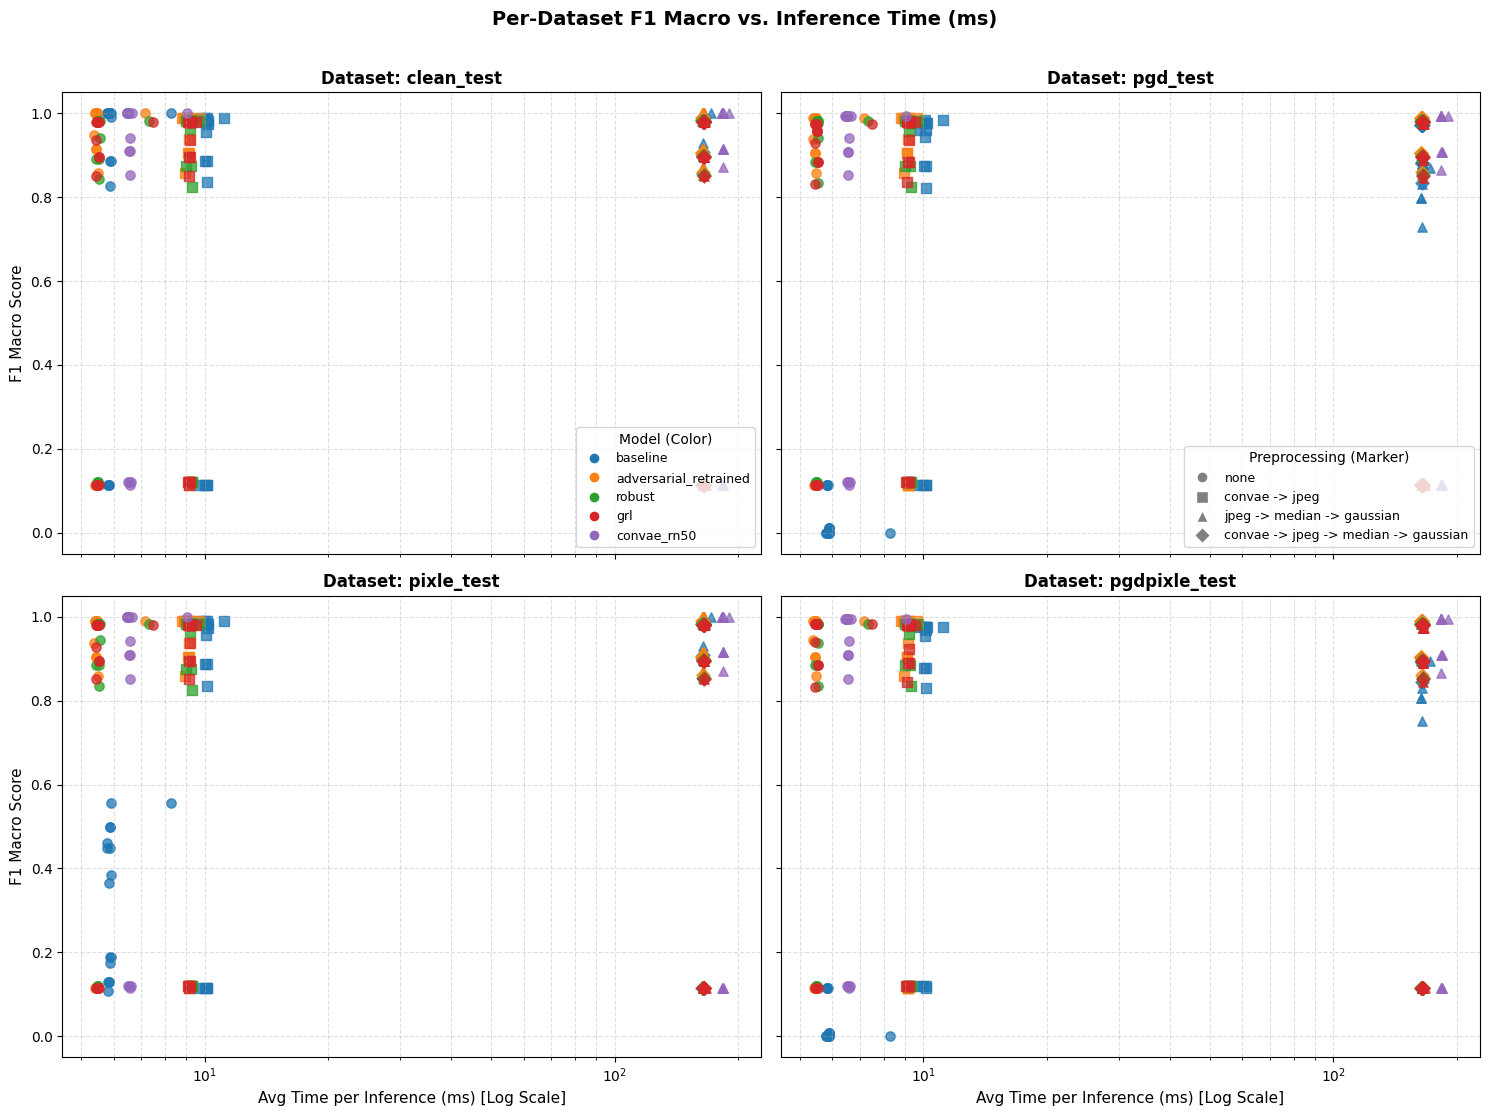

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
datasets = ["clean_test", "pgd_test", "pixle_test", "pgdpixle_test"]
models = big_df["model"].unique()
colors = plt.cm.tab10.colors
model_color = {m: colors[i % len(colors)] for i, m in enumerate(models)}
preproc_markers = {
    "none": "o",
    "convae -> jpeg": "s",
    "jpeg -> median -> gaussian": "^",
    "convae -> jpeg -> median -> gaussian": "D"
}

for idx, ds in enumerate(datasets):
    ax = axes[idx // 2, idx % 2]
    sub = big_df[big_df["dataset"] == ds]
    for m in models:
        for pp, marker in preproc_markers.items():
            pts = sub[(sub["model"] == m) & (sub["preprocessing"] == pp)]
            if len(pts) > 0:
                ax.scatter(
                    pts["Avg Time per Inference (ms)"],
                    pts["f1_macro"],
                    color=model_color[m],
                    marker=marker,
                    alpha=0.75,
                    s=45
                )
    ax.set_xscale("log")
    ax.set_title(f"Dataset: {ds}", fontsize=12, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", alpha=0.4)
    if idx // 2 == 1:
        ax.set_xlabel("Avg Time per Inference (ms) [Log Scale]", fontsize=11)
    if idx % 2 == 0:
        ax.set_ylabel("F1 Macro Score", fontsize=11)

handles_model = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=model_color[m], markersize=8, label=m) for m in models]
handles_pp = [plt.Line2D([0], [0], marker=mk, color="w", markerfacecolor="gray", markersize=8, label=pp) for pp, mk in preproc_markers.items()]
axes[0, 0].legend(handles=handles_model, title="Model (Color)", loc="lower right", fontsize=9)
axes[0, 1].legend(handles=handles_pp, title="Preprocessing (Marker)", loc="lower right", fontsize=9)

plt.suptitle("Per-Dataset F1 Macro vs. Inference Time (ms)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()